# VAMP and TCCA
Compare the performance of VAMP and other method to approximating the Koopman operator

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy  as sp

# from scipy.linalg import fractional_matrix_power
# import sys
# sys.path.append('./utils')

# import h5py
import importlib
# import analysis
# import datasets as ds
import seaborn as sns

# %matplotlib ipympl
# %matplotlib inline
from deeptime.decomposition import VAMP, EDMD, DMD, KernelCCA, KernelEDMD
from deeptime.clustering import KMeans
from deeptime.decomposition import vamp_score_cv
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.16.0) and __version__ (0.19.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace
MESA-INTEL: warning: Performance support disabled, consider sysctl dev.i915.perf_stream_paranoid=0

Detected skylake derivative running on mesa i915. Clears to srgb textures will use manual shader clears.
Detected skylake derivative running on mesa i915. Clears to srgb textures will use manual shader clears.
Detected skylake derivative running on mesa i915. Clears to srgb textures will use manual shader clears.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅ (default),Intel(R) UHD Graphics 620 (KBL GT2),IntegratedGPU,Vulkan,Mesa 20.3.5
❌,Mesa Intel(R) UHD Graphics 620 (KBL GT2),IntegratedGPU,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.3.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.16.0.post101+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.
Detected skylake derivative running on mesa i915. Clears to srgb textures will use manual shader clears.
Detected skylake derivative running on mesa i915. Clears to srgb textures will use manual shader clears.


In [2]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [3]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=150,
    n_components=1,
    noise=0.1,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=1,
    firing_prop=0.05,
)

In [4]:
X.shape

(1, 150)

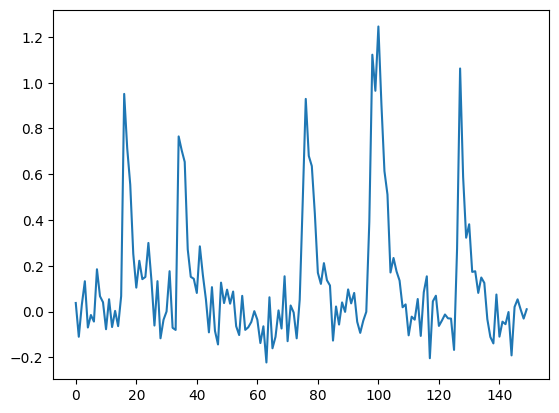

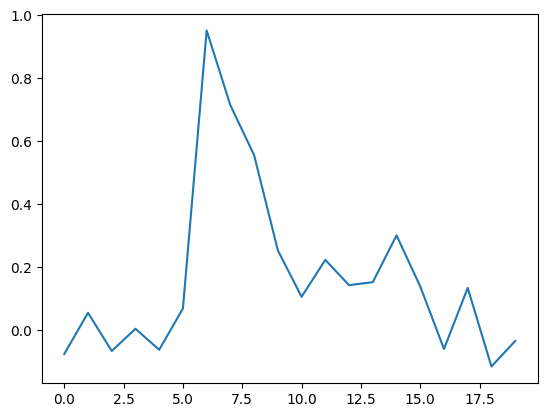

In [5]:
plt.plot(X[0])
plt.show()
plt.plot(X.ravel()[10:30])

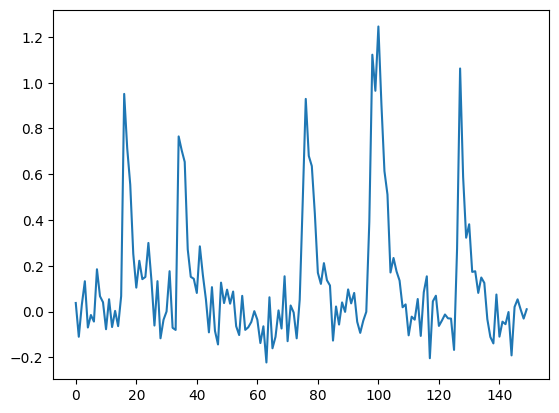

In [8]:
# tanh transient
traj = X.ravel()
# plt.plot(traj[:1000])
# add noise to the trajectory
# noise_std = 0.04
# traj_noise = traj + noise_std * np.random.randn(traj.size)
traj_noise = traj
plt.figure()
plt.plot(traj_noise)

In [9]:
# define the function to perform VAMP decomposition
from deeptime.basis import Monomials, Identity
def vamp_estimator(dim, lagtime, basis=Identity()):
    vamp_model =  VAMP(dim=dim,  # projection dimension
                       lagtime=lagtime,  # lag time
    observable_transform=basis,  # kernel embedding
    )
    return vamp_model

### Lag vector

In [26]:
# prepare the lag vectors
lag = 5
H = sp.linalg.hankel(traj_noise[:lag], traj_noise[lag-1:])
num_sample = H.shape[1]//lag - 1

# make sure there is no overlap between past and future
H_past = H[:,0:num_sample*lag:lag]
H_future = H[:,lag:(num_sample*lag+lag):lag]
# make sure H_past and H_future have the same shape
assert H_past.shape == H_future.shape

<Axes: >

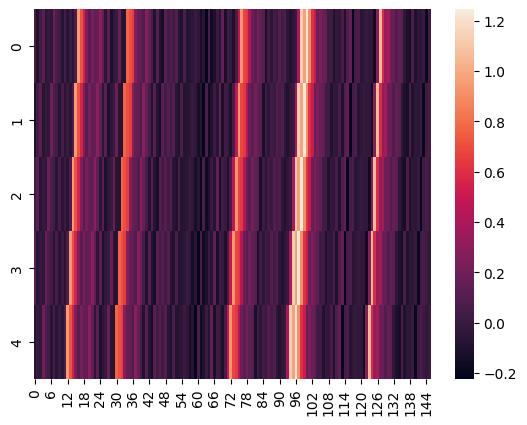

In [27]:
sns.heatmap(H)

In [28]:
vamp_est = vamp_estimator(dim=3, lagtime=1)
vamp_model = vamp_est.fit(H_past.T).fetch_model()

# estimate the VAMP score
# scores = vamp_score_cv(vamp_est.fit(H_past.T), H.T, blocksize=100, random_state=42)
# print the average Vamp score
# print(f"Average Vamp score: {scores.mean()}")

# transform the data
projection = vamp_model.transform(H_past.T)
# print(f"Projection shape: {projection.shape}\n")

<Axes: >

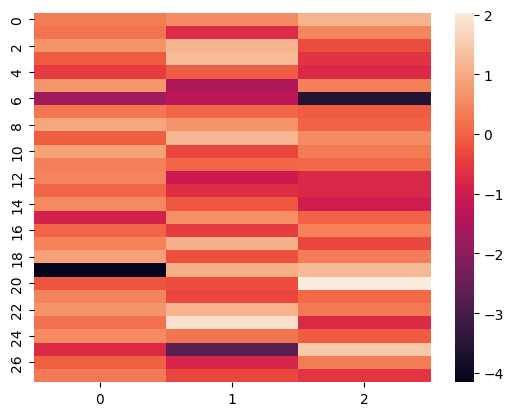

In [29]:
sns.heatmap(projection)

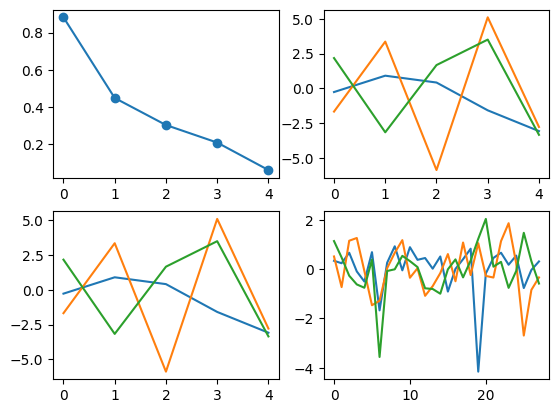

In [30]:
# make 2 by 2 plots, the first one is singular values, the second one is the first left singular vector
# the thrid one is the projection and the 4th one is the 3D scatter of the projection

fig, ax = plt.subplots(2,2)
ax[0,0].plot(vamp_model.singular_values[:],'o-')
ax[0,1].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,0].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,1].plot(projection)

Text(0.5, 0, 'Projection 3')

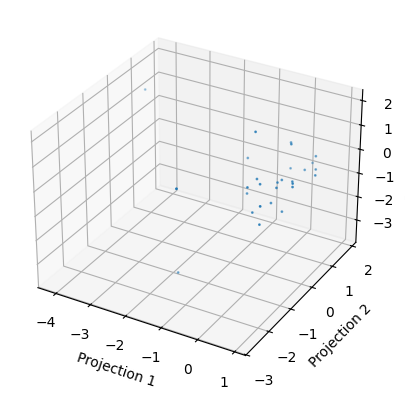

In [31]:
# Scatter of the 3D projection
num_point = 100
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(projection[:num_point,0], projection[:num_point,1], projection[:num_point,2],s=1)
# add axis labels
ax.set_xlabel('Projection 1')
ax.set_ylabel('Projection 2')
ax.set_zlabel('Projection 3')
# ax.view_init(30, 45)

### Nominals as basis function

We use the following momonial basis function up to order $M$,
$$\{1, x_1^px_2^q\cdot x_n^l\}, \quad p + q + \cdots + l \le M$$
for a given input vector $\vec{x}$

In [33]:
# we will use short lag vectors, so we will first subsample the input
sub_sample = 5
traj_sub = traj_noise

# plt.plot(traj_sub[:50])
lag = 5
H = sp.linalg.hankel(traj_sub[:lag], traj_sub[lag-1:])


<Axes: >

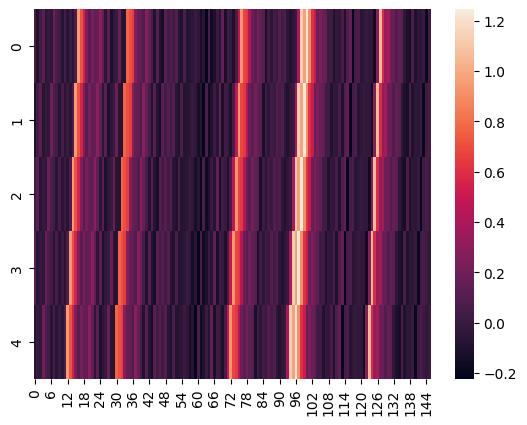

In [34]:
fig,ax = plt.subplots()
sns.heatmap(H)

<Axes: >

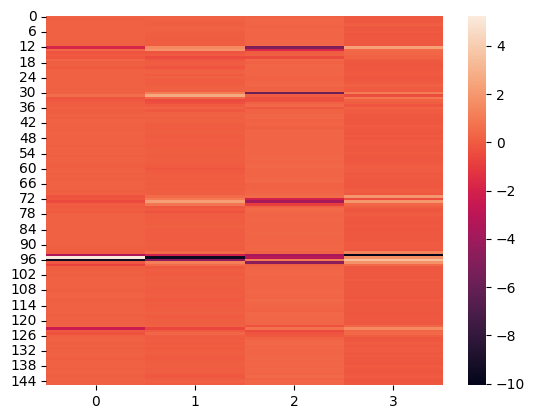

In [61]:
degree = lag
higher_order = 4
basis = Monomials(p=higher_order, d=degree)
vamp_est = vamp_estimator(dim=4, lagtime=5, basis=basis)
vamp_model = vamp_est.fit(H.T).fetch_model()

# estimate the VAMP score
# scores = vamp_score_cv(vamp_est.fit(H.T), H.T, blocksize=100, random_state=42)
# print the average Vamp score
# print(f"Average Vamp score: {scores.mean()}")

# transform the data
projection = vamp_model.transform(H.T).real
sns.heatmap(projection)
# print(f"Projection shape: {projection.shape}\n")

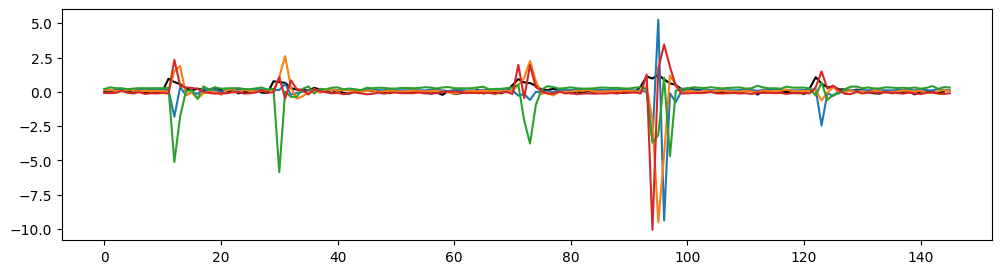

In [62]:
fig = plt.figure(figsize=(12, 3))
plt.plot(X.ravel()[lag:], c="k")
plt.plot(projection)

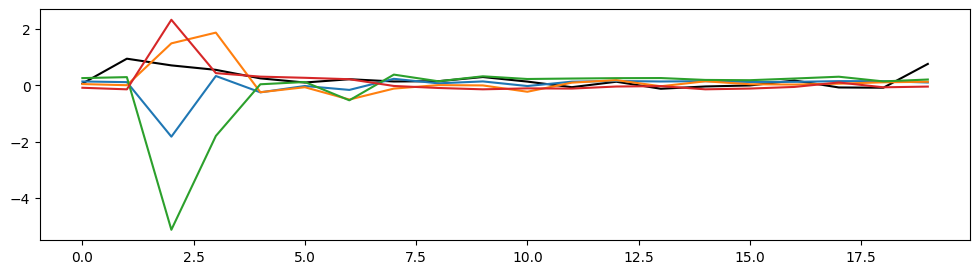

In [63]:
fig = plt.figure(figsize=(12, 3))
plt.plot(X.ravel()[lag+10:lag+30], c="k")
plt.plot(projection[10:30])

Text(0.5, 0.98, 'moniomial basis, order5, higher order 4')

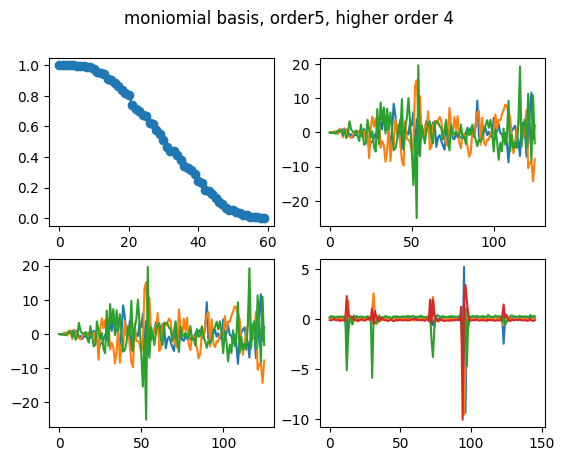

In [64]:
# make 2 by 2 plots, the first one is singular values, the second one is the first left singular vector
# the thrid one is the projection and the 4th one is the 3D scatter of the projection

fig, ax = plt.subplots(2,2)
ax[0,0].plot(vamp_model.singular_values[:],'o-')
ax[0,1].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,0].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,1].plot(projection)
# add figure title
fig.suptitle("moniomial basis, order" + str(degree) + ", higher order " + str(higher_order))
# plt.close()

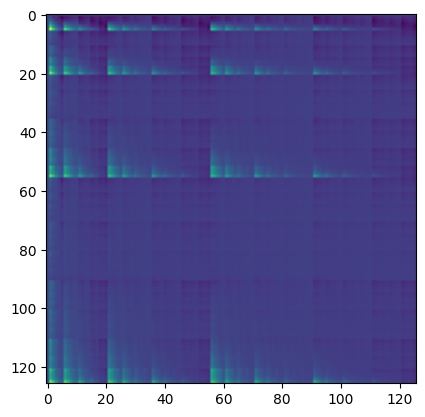

In [54]:
plt.figure()
plt.imshow(vamp_model.cov_0t)
plt.show()

In [22]:
projection.shape

(146, 4)

In [23]:
projection.shape

(146, 4)